# PLot en ratio for protons and electrons

In [13]:
import numpy as np
import os
import astropy.units as u
import astropy.constants as const
import matplotlib.pyplot as plt
import matplotlib.lines as mlines
import h5py

In [14]:
fig_dir = "/home/kwatanabe/Projects/cr-bowshocks/figures"
data_dir = "/home/kwatanabe/Projects/cr-bowshocks/crbowshock_analysis_tools/data"


with h5py.File(f"{data_dir}/steady_state_spectrum.h5", "r") as f:
    alpha_inj_grid = f["alpha_inj_grid"][()]
    log10_dens_grid = f["log10_dens_grid"][()]
    alpha_inj_e_grid = f["alpha_inj_e_grid"][()]
    log10_B_grid = f["log10_B_grid"][()]

    prot_mom_grid = f["proton/mom_grid"]
    log10_enpratio_grid = f["proton/log10_enpratio_grid"][()]

    ele_mom_grid = f["electron/mom_grid"][()]
    log10_eneratio_grid = f["electron/log10_eneratio_grid"][()]
    log10_ensynchratio_grid = f["electron/log10_ensynchratio_grid"][()]

plotting for proton

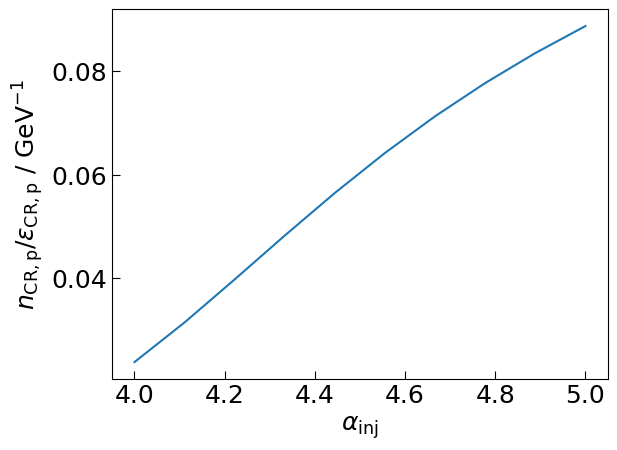

In [15]:
dens_idx = np.digitize(-20, log10_dens_grid, right=True)
fig, ax = plt.subplots()
ax.plot(alpha_inj_grid, 1 / 10**log10_enpratio_grid[:,dens_idx])
ax.set_xlabel(r"$\alpha_\mathrm{inj}$", fontsize=18)
ax.set_ylabel(r"$n_\mathrm{CR, p} / \epsilon_\mathrm{CR, p}$ / GeV$^{-1}$", fontsize=18)

ax.tick_params(axis="both", direction="in", which="major", size=6, labelsize=18)
ax.tick_params(axis="both", direction="in", which="minor", size=4, labelsize=16)

plotting for electron

In [16]:
selected_alphas = [4, 4.2, 4.4]
alpha_inj_colors = ["b", "r", "g"]
alpha_inj_handles = []

for ia, alpha_inj in enumerate(selected_alphas):
    alpha_inj_handles.append(
        mlines.Line2D(
            [0],
            [0],
            color=alpha_inj_colors[ia],
            lw=2.0,
            alpha=0.8,
            label=rf"$\alpha_\mathrm{{inj, e}} = {alpha_inj}$",
        )
    )

selected_Bfields = [1e-4, 1e-6, 1e-8]
Bfield_lss = ["-", "--", ":"]
bfield_handles = []
for ib, bfield in enumerate(selected_Bfields):
    bfield_handles.append(
        mlines.Line2D(
            [0],
            [0],
            color="k",
            ls=Bfield_lss[ib],
            lw=2.0,
            alpha=0.8,
            label=rf"$\log_{{10}}(B / \mathrm{{G}}) = {np.log10(bfield):.0f}$",
        )
    )

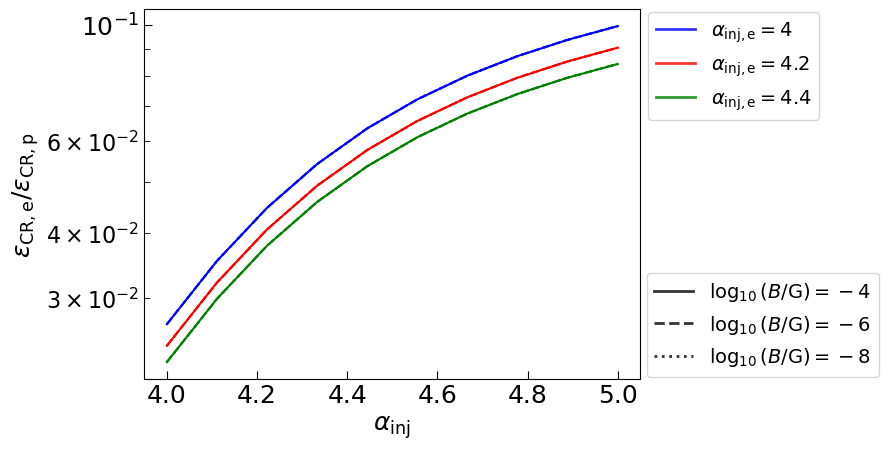

In [17]:
dens_idx = np.digitize(-20, log10_dens_grid, right=True)
fig, ax = plt.subplots()
for ib, bfield in enumerate(selected_Bfields):
    bfield_idx = np.digitize(bfield, 10**log10_B_grid, right=True)
    for ia, alpha_inj_e in enumerate(selected_alphas):
        alpha_inj_e_idx = np.digitize(alpha_inj_e, alpha_inj_e_grid, right=True)
        ax.semilogy(
            alpha_inj_grid,
            1 / (10 ** log10_eneratio_grid[:, dens_idx, alpha_inj_e_idx, bfield_idx]),
            ls=Bfield_lss[ib],
            color=alpha_inj_colors[ia],
        )
ax.set_xlabel(r"$\alpha_\mathrm{inj}$", fontsize=18)
ax.set_ylabel(r"$\epsilon_\mathrm{CR, e} / \epsilon_\mathrm{CR, p}$", fontsize=18)

ax.tick_params(axis="both", direction="in", which="major", size=6, labelsize=18)
ax.tick_params(axis="both", direction="in", which="minor", size=4, labelsize=16)

leg1 = ax.legend(
    handles=alpha_inj_handles,
    loc="upper right",
    prop={"size": 14},
    bbox_to_anchor=[1.38, 1.02],
)
ax.add_artist(leg1)
ax.legend(
    handles=bfield_handles,
    loc="lower right",
    prop={"size": 14},
    bbox_to_anchor=[1.5, -0.02],
)

for synchrotron electrons

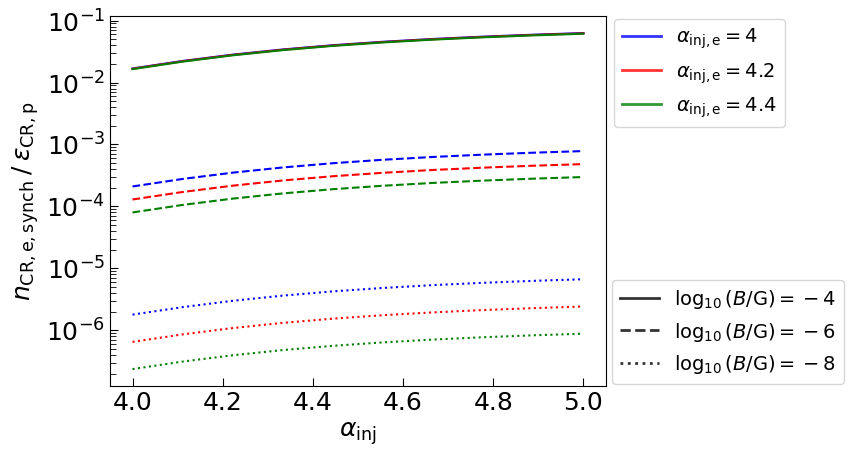

In [19]:
fig, ax = plt.subplots()
for ib, bfield in enumerate(selected_Bfields):
    bfield_idx = np.digitize(bfield, 10**log10_B_grid, right=True)
    for ia, alpha_inj_e in enumerate(selected_alphas):
        alpha_inj_e_idx = np.digitize(alpha_inj_e, alpha_inj_e_grid, right=True)
        ax.semilogy(
            alpha_inj_grid,
            1 / (10 ** log10_ensynchratio_grid[:, dens_idx, alpha_inj_e_idx, bfield_idx, 0]),
            ls=Bfield_lss[ib],
            color=alpha_inj_colors[ia],
        )
ax.set_xlabel(r"$\alpha_\mathrm{inj}$", fontsize=18)
ax.set_ylabel(
    r"$n_\mathrm{CR, e, synch} \: / \: \epsilon_\mathrm{CR, p}$",
    fontsize=18,
)

ax.tick_params(axis="both", direction="in", which="major", size=6, labelsize=18)
ax.tick_params(axis="both", direction="in", which="minor", size=4, labelsize=16)

leg1 = ax.legend(
    handles=alpha_inj_handles,
    loc="upper right",
    prop={"size": 14},
    bbox_to_anchor=[1.38, 1.02],
)
ax.add_artist(leg1)
ax.legend(
    handles=bfield_handles,
    loc="lower right",
    prop={"size": 14},
    bbox_to_anchor=[1.5, -0.02],
)